In [2]:
import scanpy as sc
import os
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd
import seaborn as sns
import numpy as np
import random
import decoupler as dc
SEED = 0
np.random.seed(SEED)
random.seed(SEED)

from matplotlib.colors import LinearSegmentedColormap

my_cmap = LinearSegmentedColormap.from_list(
    "soft_rdbl", ["#53b1dc", "#FFFFFF", "#EE6677"], N=256
)





figure_save_path = "../results/Fig_7_figures"
os.makedirs(figure_save_path, exist_ok=True)

In [3]:
def apply_pca(pdata):
    pdata = pdata.copy()
    pdata.layers["counts"] = pdata.X.copy()
    
    # Normalize, scale and compute pca
    sc.pp.normalize_total(pdata, target_sum=1e4)
    sc.pp.log1p(pdata)
    sc.pp.scale(pdata, max_value=10)
    sc.tl.pca(pdata)
    
    # Return raw counts to X
    dc.pp.swap_layer(adata=pdata, key="counts", inplace=True)

    return pdata

In [36]:
pdata = sc.read("../data/bulk_pca_combined_min.h5ad")

In [37]:
pca_pdata = apply_pca(pdata)

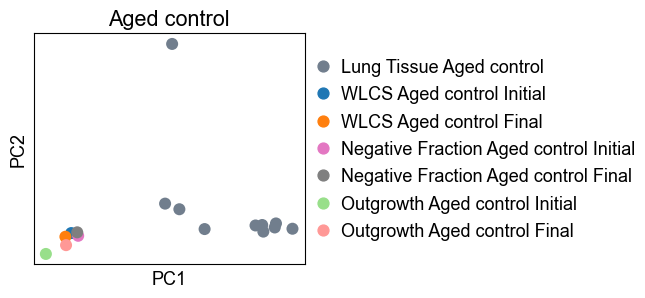

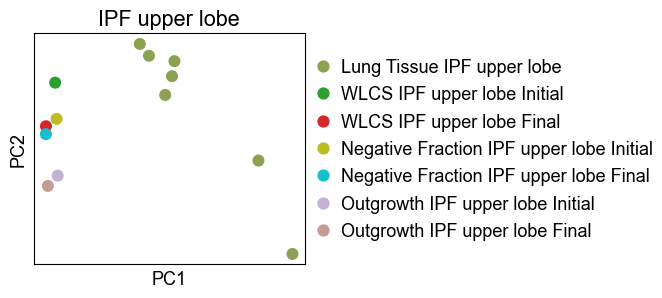

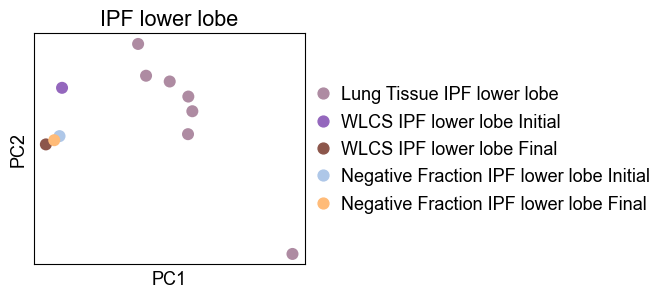

In [38]:
conditions = ['Aged control', 'IPF upper lobe', 'IPF lower lobe']
with plt.rc_context({'figure.figsize': (3.5, 3), 'font.size': 13,
                    'legend.fontsize': 13, 'legend.markerscale': 1.3}):
    for con in conditions:
        fig = sc.pl.pca(
            pca_pdata[pca_pdata.obs['Condition'] == con],
            color=["Protocol_Passage_Condition"],
            size=300,
            title=con,
            return_fig=True,
            show=False
        )
        fig.savefig(os.path.join(figure_save_path, f"pca_{con.replace(' ', '_')}.pdf"))
        
        plt.show()
